# Multi-Representation Shallow Encoders for LLMs — minimal run

**Question:** under the same trainable-parameter budget, is it better to use one large encoder for a single 3D representation, or several small encoders (mesh / point cloud / multi-view) aggregated into a frozen LLM?

Pipeline: synthetic 3D scenes → 3 representations → shallow encoders → aggregator (MLP or Q-Former) → K soft tokens → frozen LLM (Qwen2.5-0.5B-Instruct).

Runs on a free Colab T4. Steps: (1) install, (2) config, (3) generate data, (3b) look at the data, (4) models, (5) load LLM, (6) train/eval, (7) run the budget sweep, (8) results, (9) textify zero-shot, (10) textify + LoRA at the same budget.


## 1. Install

In [1]:
!pip -q install trimesh transformers accelerate

## 2. Config

In [2]:
import math, json, os, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

CFG = dict(
    seed=0,
    data="v3",             # v3: + 14 colors in shading-confusable pairs, lit colors everywhere
                           # v2: random tessellation, compound objects, 6 tasks; v1: fixed tessellation, 4 tasks
    n_train=7200, n_test=900,   # 1200 / 150 scenes per task
    n_points=512,          # point cloud size (xyz only, no color)
    view_res=32, n_views=3,  # rasterized + shaded renders (front / side / top); encoder pools to 4x4 tokens/view
    v_max=320,             # max mesh vertices per scene (padded); v2 worst case is 3 compounds
    K=16,                  # number of soft tokens fed to the LLM (fixed for all settings)
    epochs=15, batch_size=64, lr=5e-4, weight_decay=0.01,   # 20 epochs fp32 took ~40 min/run on a T4
    curve_n=300,           # test examples evaluated after every epoch (learning curve)
    amp=True,              # fp16 autocast for the frozen LLM forward/backward (T4 tensor cores); weights stay fp32
    q_cond=True,           # aggregator also reads the question (InstructBLIP-style), so the K tokens can focus on the
                           # object the question names; False = question-agnostic scene tokens (runs before 11/8)
    out_scale=True,        # RMS-normalize the soft tokens and scale them to the RMS of the LLM's own token embeddings
    grad_clip=1.0,         # clip the global gradient norm (all settings); None = off (runs before 11/8)
    rep_dropout=0.0,       # drop a whole representation during training (multi-rep only); needs longer training
    llm_name="Qwen/Qwen2.5-0.5B-Instruct",
)
device = "cuda" if torch.cuda.is_available() else "cpu"
AMP = CFG["amp"] and device == "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["seed"])
print("device:", device)

device: cuda


## 3. Synthetic 3D scenes → mesh graph / point cloud (xyz) / multi-view renders (RGB + depth + mask)
Views are real triangle rasterizations (z-buffer, Lambertian shading, 2x supersampling) done in numpy, so nothing beyond `trimesh` is needed on Colab.

**Data v3.** 14 colors in 7 bright/dark pairs (red/maroon, orange/brown, yellow/olive, lime/green, cyan/teal, blue/navy, white/gray) that become nearly the same RGB once lit: the shadow side of the bright one matches the lit side of the dark one. One world light shades the renders, the point colors and the mesh vertex colors alike, so no representation ever sees a raw albedo; the answer is still the albedo name. **From v2:** 9 shapes = 5 primitives + 4 compounds (snowman, rocket, mushroom, table; two unwelded parts each). Every mesh gets a random tessellation, so vertex count no longer identifies the shape. 6 balanced tasks; four of them (color, shape_of_color, color_of_shape, left_of) cannot be answered from the mesh alone. Categories are hypotheses; verify them with the single-rep runs.

In [3]:
# ---------- Synthetic 3D scenes ----------
import trimesh
from trimesh.transformations import random_rotation_matrix

PRIMITIVES = ["cube", "sphere", "cylinder", "cone", "torus"]
COMPOUNDS = ["snowman", "rocket", "mushroom", "table"]     # two primitives, not welded -> 2 mesh components
SHAPES = PRIMITIVES + COMPOUNDS
# Albedo. 7 bright/dark pairs: each dark color is ~half its partner with a slight hue shift, so the shadow side of
# the bright one and the lit side of the dark one end up nearly the same RGB (e.g. orange in shadow ~ lit brown,
# white in shadow ~ lit gray). The answer is always the albedo name; telling them apart needs the whole object.
COLORS = {
    "red":    (0.86, 0.13, 0.13), "maroon": (0.46, 0.07, 0.10),
    "orange": (0.96, 0.52, 0.10), "brown":  (0.50, 0.28, 0.08),
    "yellow": (0.95, 0.86, 0.12), "olive":  (0.50, 0.47, 0.08),
    "lime":   (0.55, 0.90, 0.20), "green":  (0.26, 0.46, 0.11),
    "cyan":   (0.15, 0.80, 0.85), "teal":   (0.06, 0.43, 0.45),
    "blue":   (0.25, 0.45, 0.95), "navy":   (0.13, 0.21, 0.47),
    "white":  (0.93, 0.93, 0.93), "gray":   (0.48, 0.48, 0.50),
}
# One directional light in world space, shared by the renders, the point colors and the mesh vertex colors
LIGHT_DIR = np.array([0.4, -0.6, 0.7]); LIGHT_DIR = LIGHT_DIR / np.linalg.norm(LIGHT_DIR)   # lights front, side and top
AMBIENT = 0.35
def shade(normals):
    """Lambertian intensity in [AMBIENT, 1] for unit normals (..., 3)."""
    return AMBIENT + (1 - AMBIENT) * np.clip(normals @ LIGHT_DIR, 0, None)
TASKS = {  # task -> category (to be verified empirically with single-rep models)
    "shape": "geometry",              # "What shape is the highest object?"
    "color": "appearance",            # color only exists in the multi-view renders
    "count": "common",                # compounds have 2 mesh components, so it is not a component count
    "shape_of_color": "binding",      # color (views) -> fine shape (mesh/points)
    "color_of_shape": "binding",      # fine shape (mesh/points) -> color (views)
    "left_of": "spatial+appearance",  # which object is which needs color; mesh alone is at chance
}

# Random tessellation: with one fixed resolution per primitive the vertex count alone identified the shape
# (cube 8, cone 12, cylinder 22, sphere 42, torus 60 -> mesh "shape" accuracy 0.99). Now each object gets a random
# base resolution and is then refined to a random vertex count drawn independently of its shape (see _refine).
def _box(rng, extents):
    m = trimesh.creation.box(extents=extents)
    return m.subdivide() if rng.random() < 0.5 else m                                    # 8 / 26 vertices
def _sphere(rng, radius, coarse=False):
    if coarse and rng.random() < 0.5: return trimesh.creation.icosphere(subdivisions=0, radius=radius)   # 12
    if rng.random() < 0.5: return trimesh.creation.icosphere(subdivisions=1, radius=radius)   # 42
    return trimesh.creation.uv_sphere(radius=radius, count=(6, 6))                       # 50
def _cylinder(rng, radius, height):
    return trimesh.creation.cylinder(radius=radius, height=height, sections=int(rng.integers(6, 15)))   # 14-30
def _cone(rng, radius, height):
    m = trimesh.creation.cone(radius=radius, height=height, sections=int(rng.integers(6, 15)))         # 8-16
    m.apply_translation([0, 0, -height / 2])                                             # trimesh puts the base at z=0
    return m.subdivide() if rng.random() < 0.5 else m                                    # or 26-50
def _torus(rng, R, r):
    return trimesh.creation.torus(major_radius=R, minor_radius=r, major_sections=int(rng.integers(6, 11)),
                                  minor_sections=int(rng.integers(3, 6)))                # 18-50

def _refine(m, rng, target):
    """Midpoint-subdivide random faces until the mesh has ~target vertices. Geometry is unchanged; the T-junctions
    this leaves also break the fixed edge/vertex ratio (Euler characteristic) that would otherwise give topology away."""
    while len(m.vertices) < target:
        k = min(len(m.faces), max(1, (target - len(m.vertices)) // 3))
        m = m.subdivide(face_index=rng.choice(len(m.faces), k, replace=False))
    return m

def make_object(shape, rng):
    """One object = one trimesh, centered on its bounding box. Compounds are 2 parts concatenated without welding."""
    if shape == "cube":     m = _box(rng, (1.4, 1.4, 1.4))
    if shape == "sphere":   m = _sphere(rng, 0.85)
    if shape == "cylinder": m = _cylinder(rng, 0.7, 1.5)
    if shape == "cone":     m = _cone(rng, 0.8, 1.6)
    if shape == "torus":    m = _torus(rng, 0.65, 0.25)
    if shape in COMPOUNDS:
        if shape == "snowman":                                                           # big ball + small ball
            parts = [(_sphere(rng, 0.5, coarse=True), -0.35), (_sphere(rng, 0.35, coarse=True), 0.47)]
        if shape == "rocket":                                                            # body + nose cone
            parts = [(_cylinder(rng, 0.35, 1.0), -0.3), (_cone(rng, 0.35, 0.7), 0.55)]
        if shape == "mushroom":                                                          # thin stem + flat cap
            cap = _sphere(rng, 0.7, coarse=True); cap.apply_transform(np.diag([1, 1, 0.45, 1]))
            parts = [(_cylinder(rng, 0.16, 0.8), -0.3), (cap, 0.15)]
        if shape == "table":                                                             # slab on a single leg
            parts = [(_box(rng, (1.4, 1.4, 0.16)), 0.4), (_cylinder(rng, 0.13, 0.9), -0.13)]
        for p, dz in parts: p.apply_translation([0, 0, dz])
        m = trimesh.util.concatenate([p for p, _ in parts])
        m.apply_scale(1.7 / m.extents.max())
    m = _refine(m, rng, int(rng.integers(20, 91)))       # vertex count independent of the shape
    m.apply_translation(-m.bounds.mean(0))
    return m

def make_scene(rng, min_n=1):
    n = int(rng.integers(min_n, 4))
    shapes = [str(s) for s in rng.choice(SHAPES, n)]
    colors = [str(c) for c in rng.choice(list(COLORS), n, replace=False)]
    zs = np.sort(rng.uniform(-0.9, 0.9, n))
    while n > 1 and np.min(np.diff(zs)) < 0.25:          # distinct heights for "highest"
        zs = np.sort(rng.uniform(-0.9, 0.9, n))
    objs = []
    for s, c, z in zip(shapes, colors, rng.permutation(zs)):
        m = make_object(s, rng)
        m.apply_transform(random_rotation_matrix(rng.random(3)))
        m.apply_scale(rng.uniform(0.25, 0.42))
        x, y = rng.uniform(-0.8, 0.8, 2)
        m.apply_translation([x, y, z])
        objs.append(dict(shape=s, color=c, mesh=m, x=float(x), z=float(z)))
    return objs

def to_mesh_graph(objs, v_max):
    xs, edges, off = [], [], 0
    for o in objs:
        m = o["mesh"]
        xs.append(np.concatenate([m.vertices, m.vertex_normals], 1))
        edges.append(m.edges_unique + off); off += len(m.vertices)
    x = np.concatenate(xs).astype(np.float32); e = np.concatenate(edges).astype(np.int16)
    assert len(x) <= v_max, len(x)
    return x, e

def to_points(objs, n_points, rng):
    """Returns xyz, color names (for debugging only) and lit RGB (albedo x shading of the sampled face)."""
    m = trimesh.util.concatenate([o["mesh"] for o in objs])
    pts, fid = trimesh.sample.sample_surface(m, n_points, seed=int(rng.integers(1 << 30)))
    owner = np.repeat(np.arange(len(objs)), [len(o["mesh"].faces) for o in objs])[fid]
    cname = np.array([objs[i]["color"] for i in owner])
    rgb = np.array([COLORS[c] for c in cname]) * shade(m.face_normals[fid])[:, None]
    perm = rng.permutation(n_points)
    return pts[perm].astype(np.float32), cname[perm], rgb[perm].astype(np.float32)

def vertex_rgb(objs):
    """Lit RGB per mesh vertex (albedo x shading of the vertex normal), same vertex order as to_mesh_graph."""
    return np.concatenate([np.array(COLORS[o["color"]]) * shade(o["mesh"].vertex_normals)[:, None] for o in objs]).astype(np.float32)

# ---------- Renderer: numpy triangle rasterizer (z-buffer + Lambertian shading), no OpenGL needed ----------
def look_from(direction, up=(0.0, 0.0, 1.0)):
    """Orthographic camera looking from `direction` at the origin. Rows = (right, up, toward-camera) in world coords."""
    t = np.asarray(direction, float); t = t / np.linalg.norm(t)
    r = np.cross(up, t)
    if np.linalg.norm(r) < 1e-6: r = np.array([1.0, 0.0, 0.0])   # looking straight down: +x is "right"
    r = r / np.linalg.norm(r)
    return np.stack([r, np.cross(t, r), t])

VIEW_CAMS = {"front": look_from((0, -1, 0)), "side": look_from((1, 0, 0)), "top": look_from((0, 0, 1))}
HERO_DIR = (1.0, -1.4, 1.0)                     # oblique camera, used only for visualization

def render(objs, cam, res, extent=1.5, ssaa=2):
    """Rasterize the scene's triangles with a z-buffer.
    Returns rgb (3,res,res) shaded colors on black, depth (res,res) in [0,1] (1 = closest, 0 = background),
    cov (res,res) pixel coverage in [0,1], obj (res,res) object index (-1 = background)."""
    V = np.concatenate([o["mesh"].vertices for o in objs]) @ cam.T          # camera coords: (right, up, toward)
    F, off = [], 0
    for o in objs: F.append(o["mesh"].faces + off); off += len(o["mesh"].vertices)
    F = np.concatenate(F)
    face_obj = np.repeat(np.arange(len(objs)), [len(o["mesh"].faces) for o in objs])
    N = np.concatenate([o["mesh"].face_normals for o in objs])             # world space
    N[(N @ cam.T)[:, 2] < 0] *= -1                                          # two-sided: use the side facing the camera
    face_rgb = np.array([COLORS[objs[i]["color"]] for i in face_obj]) * shade(N)[:, None]   # flat Lambertian, world light

    R = res * ssaa                                                          # supersample, then box-filter down
    X = (V[:, 0] + extent) / (2 * extent) * R                               # pixel column
    Y = (extent - V[:, 1]) / (2 * extent) * R                               # pixel row (image y points down)
    Z = V[:, 2]                                                             # larger = closer to the camera
    (ax, bx, cx), (ay, by, cy), (az, bz, cz) = (A[F].T[..., None] for A in (X, Y, Z))   # each (F, 1)
    den = (bx - ax) * (cy - ay) - (by - ay) * (cx - ax)
    den[np.abs(den) < 1e-12] = np.nan                                       # degenerate (edge-on) triangles never hit
    # only test the pixels inside each triangle's bounding box: (F, W*W) candidates instead of (F, R*R)
    x0 = np.floor(np.minimum(np.minimum(ax, bx), cx)).astype(int)
    y0 = np.floor(np.minimum(np.minimum(ay, by), cy)).astype(int)
    W = int(max((np.ceil(np.maximum(np.maximum(ax, bx), cx)) - x0).max(),
                (np.ceil(np.maximum(np.maximum(ay, by), cy)) - y0).max())) + 1
    oy, ox = (g.ravel()[None] for g in np.mgrid[0:W, 0:W])
    col, row = x0 + ox, y0 + oy                                             # (F, W*W)
    px, py = col + 0.5, row + 0.5                                           # pixel centers
    dx, dy = px - ax, py - ay
    wb = (dx * (cy - ay) - dy * (cx - ax)) / den
    wc = ((bx - ax) * dy - (by - ay) * dx) / den
    wa = 1 - wb - wc
    z = wa * az + wb * bz + wc * cz
    hit = (wa >= -1e-7) & (wb >= -1e-7) & (wc >= -1e-7) & (col >= 0) & (col < R) & (row >= 0) & (row < R)
    pix, face, z = (row * R + col)[hit], np.nonzero(hit)[0], z[hit]
    o = np.lexsort((z, pix)); pix, face, z = pix[o], face[o], z[o]          # per pixel, closest fragment is last
    last = np.r_[pix[1:] != pix[:-1], True]
    zbuf = np.full(R * R, -np.inf); fbuf = np.full(R * R, -1)
    zbuf[pix[last]], fbuf[pix[last]] = z[last], face[last]

    hit = fbuf >= 0
    rgb = np.where(hit[:, None], face_rgb[fbuf], 0.0)
    depth = np.where(hit, np.clip((zbuf + extent) / (2 * extent), 0, 1), 0.0)
    obj = np.where(hit, face_obj[fbuf], -1).reshape(R, R)[ssaa // 2::ssaa, ssaa // 2::ssaa]
    down = lambda a: a.reshape(res, ssaa, res, ssaa, *a.shape[2:]).mean((1, 3))
    rgb = down(rgb.reshape(R, R, 3)).transpose(2, 0, 1)
    return dict(rgb=rgb, depth=down(depth.reshape(R, R)), cov=down(hit.reshape(R, R).astype(float)), obj=obj)

def to_views(objs, res, ssaa=2):
    """Model input: front / side / top orthographic renders, 5 channels = RGB + depth + coverage mask."""
    out = np.zeros((len(VIEW_CAMS), 5, res, res), np.float32)
    for vi, cam in enumerate(VIEW_CAMS.values()):
        r = render(objs, cam, res, ssaa=ssaa)
        out[vi, 0:3], out[vi, 3], out[vi, 4] = r["rgb"], r["depth"], r["cov"]
    return out

def make_question(objs, rng, task=None):
    """Returns (task, question, answer), or None if this scene cannot pose the task."""
    task = task or str(rng.choice(list(TASKS)))
    top = max(objs, key=lambda o: o["z"])
    if task == "shape":
        return task, "What shape is the highest object?", top["shape"]
    if task == "color":
        return task, "What color is the highest object?", top["color"]
    if task == "count":
        return task, "How many objects are there?", str(len(objs))
    if task == "shape_of_color":
        o = objs[int(rng.integers(len(objs)))]
        return task, f"What shape is the {o['color']} object?", o["shape"]
    if task == "color_of_shape":                          # needs a shape that occurs exactly once
        uniq = [o for o in objs if sum(p["shape"] == o["shape"] for p in objs) == 1]
        if not uniq: return None
        o = uniq[int(rng.integers(len(uniq)))]
        return task, f"What color is the {o['shape']}?", o["color"]
    if task == "left_of":                                 # front camera: image right = +x; ordered pairs -> yes/no balanced
        pairs = [(a, b) for a in objs for b in objs if a is not b and abs(a["x"] - b["x"]) >= 0.3]
        if not pairs: return None
        a, b = pairs[int(rng.integers(len(pairs)))]
        return task, f"Seen from the front, is the {a['color']} object left of the {b['color']} object?", \
               "yes" if a["x"] < b["x"] else "no"
    raise ValueError(task)

def build_split(n, seed):
    rng = np.random.default_rng(seed)
    data = []
    for i in range(n):
        task = list(TASKS)[i % len(TASKS)]               # balanced tasks
        while True:                                       # resample until the scene can pose this task
            objs = make_scene(rng, min_n=2 if task == "left_of" else 1)
            qa = make_question(objs, rng, task)
            if qa is not None: break
        task, q, a = qa
        mx, me = to_mesh_graph(objs, CFG["v_max"])
        pts, pcol, prgb = to_points(objs, CFG["n_points"], rng)
        data.append(dict(points=pts, point_colors=pcol, views=to_views(objs, CFG["view_res"]),
                         point_rgb=prgb, mesh_rgb=vertex_rgb(objs),                # lit colors (used by color=True models)
                         mesh_x=mx, mesh_e=me, task=task, q=q, a=a,
                         scene=[(o["shape"], o["color"], o["x"], o["z"]) for o in objs]))
    return data

t0 = time.time()
train_data = build_split(CFG["n_train"], seed=1)
test_data = build_split(CFG["n_test"], seed=2)
print(f"generated {len(train_data)}/{len(test_data)} scenes in {time.time()-t0:.0f}s")
print(test_data[0]["q"], "->", test_data[0]["a"])

generated 7200/900 scenes in 131s
What shape is the highest object? -> cube


## 3b. Look at the data
Each row is one scene: a high-res oblique render (for humans only), then exactly what each encoder receives. Also prints majority-class accuracy per task so the results in section 8 can be read against chance. Saves `scene_examples.png` for the slides.

/tmp/ipykernel_5404/4047183275.py:46: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(h_pad=5)


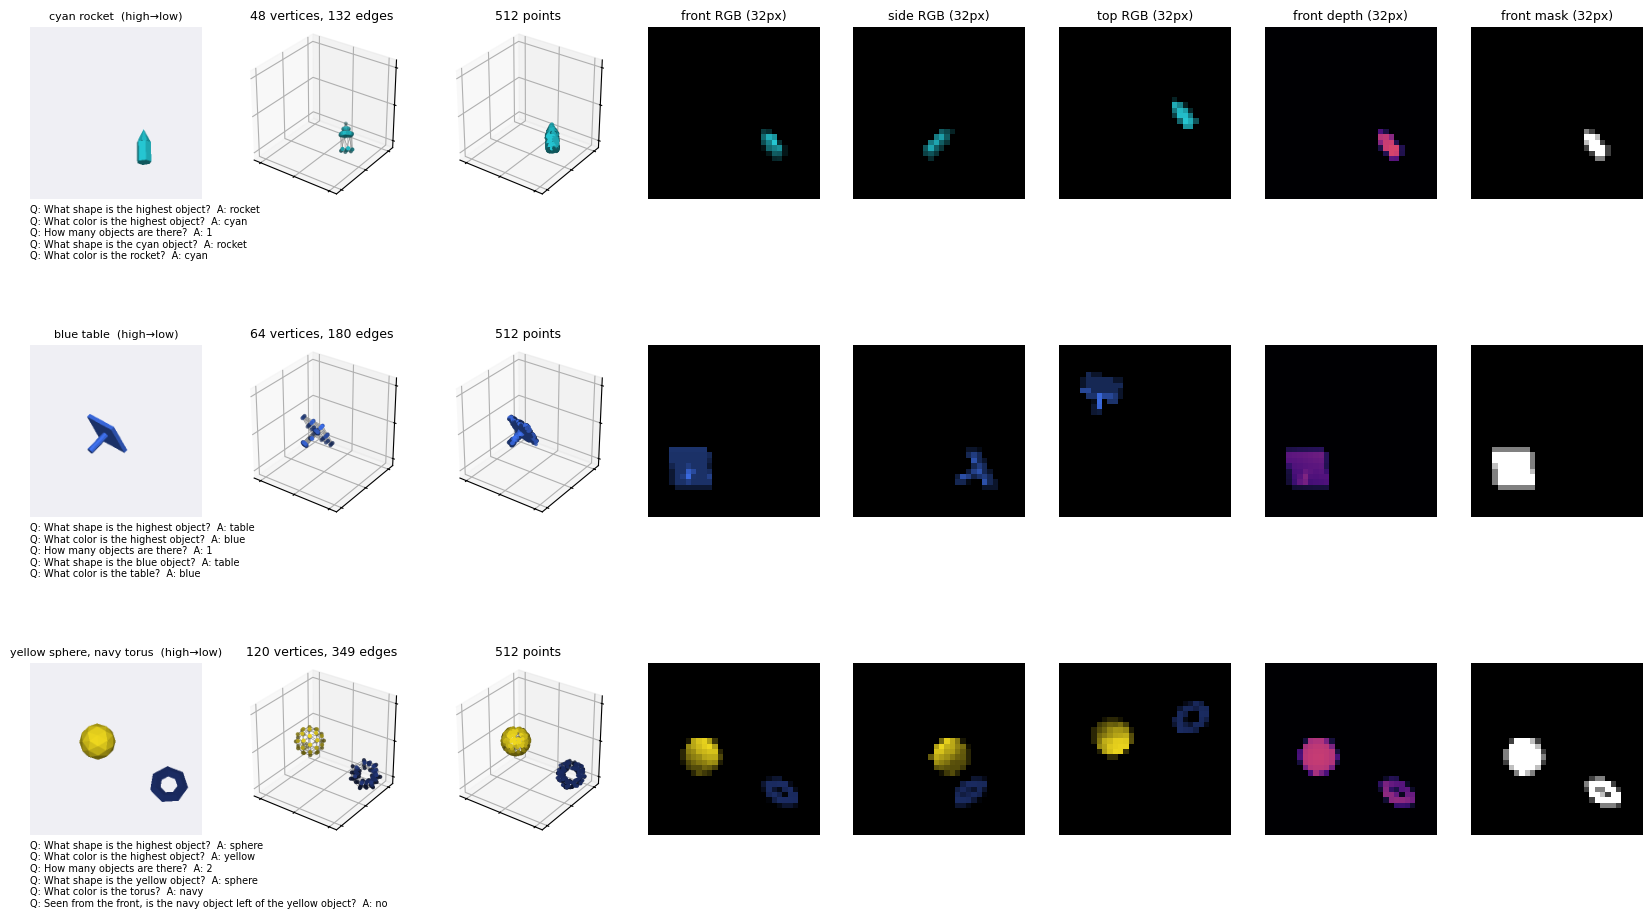

shape from mesh topology alone (held-out kNN): 0.38   chance 0.11


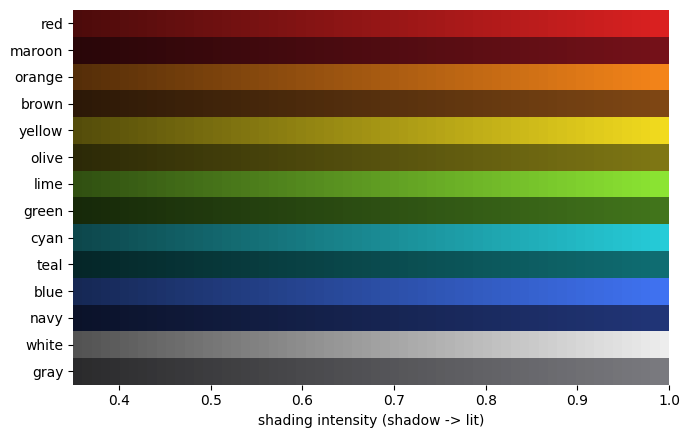

closest pairs after lighting (min RGB distance): blue/navy 0.010, white/gray 0.011, yellow/olive 0.013, cyan/teal 0.013, lime/green 0.015, orange/brown 0.019, red/maroon 0.020, brown/olive 0.058
shape           majority-class acc 0.15  (9 answers)
color           majority-class acc 0.13  (14 answers)
count           majority-class acc 0.37  (3 answers)
shape_of_color  majority-class acc 0.22  (9 answers)
color_of_shape  majority-class acc 0.11  (14 answers)
left_of         majority-class acc 0.54  (2 answers)


In [4]:
# ---------- Look at the data: what each encoder actually receives ----------
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection

def _setup3d(ax, title):
    d = np.asarray(HERO_DIR, float)
    ax.view_init(elev=np.degrees(np.arctan2(d[2], np.hypot(d[0], d[1]))), azim=np.degrees(np.arctan2(d[1], d[0])))
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_zlim(-1.2, 1.2); ax.set_box_aspect((1, 1, 1))
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([]); ax.set_title(title, fontsize=9)

def show_examples(n=3, seed=123, hero_res=192, save="scene_examples.png"):
    """Regenerates n scenes with the same functions as build_split and plots every model input next to a
    high-res oblique render (the render is for humans only; the model never sees it)."""
    rng = np.random.default_rng(seed)
    cols = ["3D render (oblique, for humans)", "mesh graph (lit vertex RGB)", "point cloud (lit RGB)",
            "front RGB", "side RGB", "top RGB", "front depth", "front mask"]
    fig = plt.figure(figsize=(2.6 * len(cols), 3.9 * n))
    for row in range(n):
        objs = make_scene(rng)
        qa = [r[1:] for t in TASKS if (r := make_question(objs, rng, task=t)) is not None]
        mx, me = to_mesh_graph(objs, CFG["v_max"])
        pts, _, prgb = to_points(objs, CFG["n_points"], rng)
        views = to_views(objs, CFG["view_res"])
        hero = render(objs, look_from(HERO_DIR), hero_res, extent=1.6, ssaa=2)
        p = lambda c: fig.add_subplot(n, len(cols), row * len(cols) + c + 1, **({"projection": "3d"} if c in (1, 2) else {}))

        ax = p(0)
        bg = np.array([0.94, 0.94, 0.96])[:, None, None]
        ax.imshow((hero["rgb"] + (1 - hero["cov"]) * bg).transpose(1, 2, 0)); ax.axis("off")
        ax.set_title(", ".join(f"{o['color']} {o['shape']}" for o in sorted(objs, key=lambda o: -o["z"])) + "  (high→low)", fontsize=8)
        ax.text(0.0, -0.03, "\n".join(f"Q: {q}  A: {a}" for q, a in qa), transform=ax.transAxes, va="top", fontsize=7)

        ax = p(1); xyz = mx[:, :3]
        ax.add_collection3d(Line3DCollection(xyz[me.astype(int)], colors="0.55", linewidths=0.4))
        ax.scatter(*xyz.T, s=4, c=vertex_rgb(objs)); _setup3d(ax, f"{len(mx)} vertices, {len(me)} edges")

        ax = p(2)
        ax.scatter(*pts.T, s=3, c=prgb); _setup3d(ax, f"{len(pts)} points")

        for vi, name in enumerate(VIEW_CAMS):
            ax = p(3 + vi); ax.imshow(views[vi, :3].transpose(1, 2, 0), interpolation="nearest"); ax.axis("off")
        ax = p(6); ax.imshow(views[0, 3], cmap="magma", vmin=0, vmax=1, interpolation="nearest"); ax.axis("off")
        ax = p(7); ax.imshow(views[0, 4], cmap="gray", vmin=0, vmax=1, interpolation="nearest"); ax.axis("off")
        if row == 0:
            for c in range(3, len(cols)): fig.axes[c].set_title(f"{cols[c]} ({CFG['view_res']}px)", fontsize=9)
    plt.tight_layout(h_pad=5)
    if save: plt.savefig(save, dpi=150, bbox_inches="tight")
    plt.show()

show_examples()

def topology_shortcut(n=3000, k=15, seed=7):
    """Can mesh topology alone (vertex count, edge count) tell the shape? Held-out kNN on single objects.
    Data v1 (fixed tessellation): 1.00. Whatever remains is real topology (torus genus, compounds = 2 parts)."""
    rng = np.random.default_rng(seed); X, y = [], []
    for s in rng.choice(SHAPES, n):
        m = make_object(str(s), rng); X.append((len(m.vertices), len(m.edges_unique))); y.append(SHAPES.index(str(s)))
    X = np.array(X, float); y = np.array(y); X = (X - X.mean(0)) / X.std(0); h = n // 2
    nn = np.argsort(((X[h:, None] - X[None, :h]) ** 2).sum(-1), 1)[:, :k]
    pred = np.array([np.bincount(r, minlength=len(SHAPES)).argmax() for r in y[:h][nn]])
    print(f"shape from mesh topology alone (held-out kNN): {(pred == y[h:]).mean():.2f}   chance {1 / len(SHAPES):.2f}")
topology_shortcut()

def show_palette(save="palette_lit.png"):
    """Each color from full shadow (ambient) to fully lit, and the color pairs whose lit ranges come closest."""
    s = np.linspace(AMBIENT, 1, 64)
    names = list(COLORS); strips = np.stack([np.outer(s, COLORS[c]) for c in names])      # (C, 64, 3)
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(names)))
    ax.imshow(strips, aspect="auto", extent=(AMBIENT, 1, len(names) - 0.5, -0.5))
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.set_xlabel("shading intensity (shadow -> lit)")
    for sp in ax.spines.values(): sp.set_visible(False)
    plt.tight_layout()
    if save: plt.savefig(save, dpi=150, bbox_inches="tight")
    plt.show()
    d = np.linalg.norm(strips[:, None, :, None] - strips[None, :, None, :], axis=-1).min((2, 3))   # closest lit RGBs
    pairs = sorted((d[a, b], names[a], names[b]) for a in range(len(names)) for b in range(a + 1, len(names)))
    print("closest pairs after lighting (min RGB distance):", ", ".join(f"{a}/{b} {v:.3f}" for v, a, b in pairs[:8]))
show_palette()

# chance levels, so the trained numbers can be read against them
for t in TASKS:
    ans = [ex["a"] for ex in test_data if ex["task"] == t]
    vals, cnt = np.unique(ans, return_counts=True)
    print(f"{t:15s} majority-class acc {cnt.max() / len(ans):.2f}  ({len(vals)} answers)")

## 4. Shallow encoders, aggregators (Q-Former / MLP), budget matching
`match_budget` picks the width so that **encoders + aggregator + output projection** hit the target parameter count (LLM excluded). Each representation gets its own LayerNorm so no encoder dominates by scale.

**Question conditioning** (`CFG['q_cond']`): the question's (frozen) LLM token embeddings are projected to the encoder width and appended to the Q-Former queries in self-attention (InstructBLIP), or mean-pooled into the MLP input, so the K soft tokens can depend on which object the question names. The projection counts toward the budget in every setting. **Output scale** (`CFG['out_scale']`): soft tokens are RMS-normalized and scaled to the RMS of the LLM's token embeddings (learnable scalar), so they enter the LLM at the same scale as text.


In [5]:
# ---------- Shallow encoders ----------
class PointEnc(nn.Module):
    """Mini PointNet: shared MLP per point, max-pooled into G local groups -> G tokens.
    Groups always come from xyz; `feats` (xyz or xyz+rgb, in_dim wide) is what the MLP sees."""
    def __init__(self, w, G=32, in_dim=3):
        super().__init__(); self.G = G
        self.mlp = nn.Sequential(nn.Linear(in_dim, w), nn.GELU(), nn.Linear(w, w), nn.GELU(), nn.Linear(w, w))
        self.pos = nn.Linear(3, w)
    def forward(self, pts, feats=None):                        # (B, N, 3), (B, N, in_dim)
        B, N, _ = pts.shape
        centers = pts[:, :self.G]                              # points are pre-shuffled -> random centers
        assign = torch.cdist(pts, centers).argmin(-1)          # (B, N)
        h = self.mlp(pts if feats is None else feats)
        tok = torch.full((B, self.G, h.size(-1)), -1e4, device=pts.device, dtype=h.dtype)
        tok = tok.scatter_reduce(1, assign[..., None].expand_as(h), h, reduce="amax", include_self=True)
        return tok + self.pos(centers), torch.zeros(B, self.G, dtype=torch.bool, device=pts.device)

class ViewEnc(nn.Module):
    """Small CNN shared across views; each view -> 4x4 spatial tokens (pooled, so any view_res works)."""
    def __init__(self, w, n_views=3):
        super().__init__()
        c = max(8, w // 2)
        self.cnn = nn.Sequential(nn.Conv2d(5, c, 3, padding=1), nn.GELU(),
                                 nn.Conv2d(c, w, 3, stride=2, padding=1), nn.GELU(),
                                 nn.Conv2d(w, w, 3, stride=2, padding=1), nn.AdaptiveAvgPool2d(4))
        self.pos = nn.Parameter(torch.randn(n_views * 16, w) * 0.02)
    def forward(self, views):                                  # (B, V, 5, H, W)
        B, V = views.shape[:2]
        h = self.cnn(views.flatten(0, 1))                      # (B*V, w, 4, 4)
        tok = h.flatten(2).transpose(1, 2).reshape(B, V * 16, -1) + self.pos
        return tok, torch.zeros(B, tok.size(1), dtype=torch.bool, device=views.device)

class MeshEnc(nn.Module):
    """Dense GIN on the mesh vertex graph -> one token per vertex. Vertex features: xyz+normal (+rgb)."""
    def __init__(self, w, layers=2, in_dim=6):
        super().__init__()
        self.inp = nn.Linear(in_dim, w)
        self.eps = nn.Parameter(torch.zeros(layers))
        self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(w, w), nn.GELU(), nn.Linear(w, w)) for _ in range(layers)])
    def forward(self, x, adj, pad):                            # (B,V,in_dim), (B,V,V), (B,V) True=pad
        h = self.inp(x)
        for e, mlp in zip(self.eps, self.mlps):
            h = h + mlp((1 + e) * h + adj @ h)
            h = h.masked_fill(pad[..., None], 0)
        return h, pad

ENCODERS = {"point": PointEnc, "view": ViewEnc, "mesh": MeshEnc}

# ---------- Aggregators ----------
class QFormerAgg(nn.Module):
    def __init__(self, d, K, layers=1, heads=4):
        super().__init__()
        self.q = nn.Parameter(torch.randn(K, d) * 0.02)
        self.layers = nn.ModuleList([nn.TransformerDecoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
                                     for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
    def forward(self, mem, pad, q=None, q_pad=None):
        """q (B, Lq, d): question tokens, appended to the learnable queries in self-attention (InstructBLIP);
        only the K query outputs are returned."""
        K = self.q.size(0); z = self.q.expand(mem.size(0), -1, -1); tpad = None
        if q is not None:
            z = torch.cat([z, q], 1)
            tpad = torch.cat([torch.zeros(q.size(0), K, dtype=torch.bool, device=q.device), q_pad], 1)
        for l in self.layers: z = l(z, mem, tgt_key_padding_mask=tpad, memory_key_padding_mask=pad)
        return self.norm(z[:, :K])

class MLPAgg(nn.Module):
    """Per-representation masked mean+max pooling (+ mean of the question tokens) -> MLP -> K tokens."""
    def __init__(self, d, K, n_reps, q_cond=False):
        super().__init__(); self.K, self.d = K, d
        self.mlp = nn.Sequential(nn.Linear(2 * d * n_reps + d * q_cond, 2 * d), nn.GELU(), nn.Linear(2 * d, K * d))
    def forward(self, toks, pads, q=None, q_pad=None):         # lists per representation
        feats = []
        if q is not None:
            keep = (~q_pad).float()[..., None]; feats.append((q * keep).sum(1) / keep.sum(1).clamp(min=1))
        for t, p in zip(toks, pads):
            keep = (~p).float()[..., None]
            mean = (t * keep).sum(1) / keep.sum(1).clamp(min=1)
            mx = t.masked_fill(p[..., None], -1e4).max(1).values * (keep.sum(1) > 0)
            feats += [mean, mx]
        return self.mlp(torch.cat(feats, -1)).view(-1, self.K, self.d)

class MultiRepAdaptor(nn.Module):
    """color=True: point and mesh encoders also get RGB (information-matched with the views).
    color=False: geometry only; color exists only in the views (complementary information).
    q_cond=True: the aggregator also reads the question (frozen LLM embeddings -> Linear -> LayerNorm).
    out_rms: if set, soft tokens are RMS-normalized and scaled to this (learnable scalar gain, init = LLM embedding RMS)."""
    def __init__(self, reps, w, agg="qformer", K=16, llm_dim=896, agg_layers=1, color=False, q_cond=False, out_rms=None):
        super().__init__()
        self.reps, self.agg_type, self.color, self.q_cond, self.out_rms = reps, agg, color, q_cond, out_rms
        in_dim = {"point": 6 if color else 3, "mesh": 9 if color else 6}
        self.enc = nn.ModuleDict({r: ENCODERS[r](w, in_dim=in_dim[r]) if r in in_dim else ENCODERS[r](w) for r in reps})
        self.norm = nn.ModuleDict({r: nn.LayerNorm(w) for r in reps})   # put every representation on the same scale
        self.type_emb = nn.Parameter(torch.randn(len(reps), w) * 0.02)
        self.agg = QFormerAgg(w, K, agg_layers) if agg == "qformer" else MLPAgg(w, K, len(reps), q_cond)
        if q_cond: self.q_proj = nn.Sequential(nn.Linear(llm_dim, w), nn.LayerNorm(w))
        self.out = nn.Linear(w, llm_dim)
        if out_rms is not None: self.gain = nn.Parameter(torch.tensor(float(out_rms)))
    def forward(self, batch, drop=None):                       # drop: (B, n_reps) bool, True = representation removed
        toks, pads = [], []
        for i, r in enumerate(self.reps):
            if r == "point":
                t, p = self.enc[r](batch["points"], torch.cat([batch["points"], batch["point_rgb"]], -1) if self.color else None)
            if r == "view":  t, p = self.enc[r](batch["views"])
            if r == "mesh":
                x = torch.cat([batch["mesh_x"], batch["mesh_rgb"]], -1) if self.color else batch["mesh_x"]
                t, p = self.enc[r](x, batch["adj"], batch["mesh_pad"])
            if drop is not None: p = p | drop[:, i:i + 1]
            toks.append(self.norm[r](t) + self.type_emb[i]); pads.append(p)
        q = q_pad = None
        if self.q_cond: q, q_pad = self.q_proj(batch["q_emb"]), batch["q_pad"]   # q_emb is added by answer_logits
        if self.agg_type == "qformer":
            mem, pad = torch.cat(toks, 1), torch.cat(pads, 1)
            z = self.agg(mem.masked_fill(pad[..., None], 0), pad, q, q_pad)
        else:
            z = self.agg(toks, pads, q, q_pad)
        z = self.out(z)                                        # (B, K, llm_dim)
        if self.out_rms is not None:                           # same scale as the LLM's own token embeddings
            z = z * torch.rsqrt(z.float().pow(2).mean(-1, keepdim=True) + 1e-6).to(z.dtype) * self.gain
        return z

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def match_budget(reps, agg, target, llm_dim=896, K=16, **kw):
    """Pick the encoder/aggregator width whose trainable-parameter count is closest to `target`.
    kw (color, q_cond, out_rms) must be the same as for the model that is then built."""
    best = None
    for w in range(16, 1025, 8):
        n = n_params(MultiRepAdaptor(reps, w, agg, K, llm_dim, **kw))
        if best is None or abs(n - target) < abs(best[1] - target): best = (w, n)
        if n > target * 1.5: break
    return best   # (width, n_params)

## 5. Frozen LLM

In [6]:
# ---------- Frozen LLM ----------
from transformers import AutoModelForCausalLM, AutoTokenizer
tok = AutoTokenizer.from_pretrained(CFG["llm_name"])
llm = AutoModelForCausalLM.from_pretrained(CFG["llm_name"], torch_dtype=torch.float32).to(device)
llm.requires_grad_(False); llm.eval()
print("LLM hidden size:", llm.config.hidden_size)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM hidden size: 896


## 6. Batching, training, evaluation
Soft tokens go in through `inputs_embeds`; loss only on answer tokens. Do **not** wrap the LLM forward in `torch.no_grad()` during training — gradients must flow through the frozen LLM into the adaptor.

Speed: the LLM runs under fp16 autocast, and the 152k-vocab LM head (~27% of the LLM's parameters) is applied only at the positions that predict answer tokens. Both leave the loss and the exact-match metric unchanged.

In [7]:
# ---------- Batching ----------
LLM_DIM = llm.config.hidden_size
embed = llm.get_input_embeddings()
EOS = tok.eos_token_id
EMB_RMS = embed.weight.float().pow(2).mean().sqrt().item()     # target scale of the soft tokens (CFG["out_scale"])
print(f"LLM token-embedding RMS {EMB_RMS:.4f}")

def encode_text(ex):
    p = tok(f"Question: {ex['q']} Answer:", add_special_tokens=False)["input_ids"]
    a = tok(" " + ex["a"], add_special_tokens=False)["input_ids"] + [EOS]
    return p, a

def collate(exs):
    B, V = len(exs), CFG["v_max"]
    mesh_x = torch.zeros(B, V, 6); mesh_rgb = torch.zeros(B, V, 3); adj = torch.zeros(B, V, V)
    mesh_pad = torch.ones(B, V, dtype=torch.bool)
    for i, ex in enumerate(exs):
        n = len(ex["mesh_x"]); mesh_x[i, :n] = torch.from_numpy(ex["mesh_x"]); mesh_pad[i, :n] = False
        mesh_rgb[i, :n] = torch.from_numpy(ex["mesh_rgb"])
        e = torch.from_numpy(ex["mesh_e"].astype(np.int64)); adj[i, e[:, 0], e[:, 1]] = 1; adj[i, e[:, 1], e[:, 0]] = 1
    texts = [encode_text(ex) for ex in exs]
    Lq = max(len(p) for p, _ in texts)                         # question only (no answer) for q_cond aggregators
    q_ids = torch.full((B, Lq), EOS, dtype=torch.long); q_pad = torch.ones(B, Lq, dtype=torch.bool)
    for i, (p, _) in enumerate(texts): q_ids[i, :len(p)] = torch.tensor(p); q_pad[i, :len(p)] = False
    L = max(len(p) + len(a) for p, a in texts)
    ids = torch.full((B, L), EOS, dtype=torch.long); labels = torch.full((B, L), -100, dtype=torch.long)
    attn = torch.zeros(B, L, dtype=torch.long)
    for i, (p, a) in enumerate(texts):
        ids[i, :len(p) + len(a)] = torch.tensor(p + a); labels[i, len(p):len(p) + len(a)] = torch.tensor(a)
        attn[i, :len(p) + len(a)] = 1
    return dict(points=torch.from_numpy(np.stack([ex["points"] for ex in exs])),
                point_rgb=torch.from_numpy(np.stack([ex["point_rgb"] for ex in exs])),
                views=torch.from_numpy(np.stack([ex["views"] for ex in exs])),
                mesh_x=mesh_x, mesh_rgb=mesh_rgb, adj=adj, mesh_pad=mesh_pad, ids=ids, labels=labels, attn=attn,
                q_ids=q_ids, q_pad=q_pad,
                task=[ex["task"] for ex in exs])

def to_dev(b): return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in b.items()}

def answer_logits(model, b, drop=None):
    """[soft tokens; prompt; answer] -> frozen LLM -> logits only where the next token is an answer token.
    Returns (logits (n, vocab) fp32, targets (n,), example index (n,))."""
    K = CFG["K"]
    if getattr(model, "q_cond", False): b = dict(b, q_emb=embed(b["q_ids"]))   # frozen embeddings of the question
    with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
        soft = model(b, drop)                                  # (B, K, H)
        x = torch.cat([soft, embed(b["ids"])], 1)
        attn = torch.cat([torch.ones(soft.shape[:2], dtype=b["attn"].dtype, device=device), b["attn"]], 1)
        h = llm.model(inputs_embeds=x, attention_mask=attn).last_hidden_state     # (B, K+L, H), final norm applied
        sel = b["labels"] != -100                              # ids position i is predicted from position K-1+i
        logits = llm.lm_head(h[:, K - 1:-1][sel])
    return logits.float(), b["labels"][sel], sel.nonzero()[:, 0]

def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=AMP)
    except (AttributeError, TypeError): return torch.cuda.amp.GradScaler(enabled=AMP)

# ---------- Train / eval ----------
def train(model, data, cfg=CFG, log_every=50, eval_data=None):
    """Returns the learning curve: test accuracy on `eval_data` after every epoch."""
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scaler = make_scaler(); curve = []
    steps = cfg["epochs"] * math.ceil(len(data) / cfg["batch_size"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, cfg["lr"], total_steps=steps, pct_start=0.05)
    model.train(); step = 0
    for ep in range(cfg["epochs"]):
        idx = np.random.permutation(len(data))
        for s in range(0, len(data), cfg["batch_size"]):
            b = to_dev(collate([data[i] for i in idx[s:s + cfg["batch_size"]]]))
            drop = None
            if len(model.reps) > 1 and cfg["rep_dropout"] > 0:
                drop = torch.rand(len(b["ids"]), len(model.reps), device=device) < cfg["rep_dropout"]
                drop[drop.all(1), 0] = False                    # always keep at least one representation
            logits, tgt, _ = answer_logits(model, b, drop)
            loss = F.cross_entropy(logits, tgt)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            if cfg.get("grad_clip"):                           # unscale first so the threshold is in real units
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            scaler.step(opt); scaler.update()
            sched.step(); step += 1
            if step % log_every == 0: print(f"  ep {ep} step {step}/{steps} loss {loss.item():.3f}")
        if eval_data is not None:
            curve.append(dict(epoch=ep + 1, **evaluate(model, eval_data)))
            print(f"  -- epoch {ep + 1}: " + " ".join(f"{k} {v:.2f}" for k, v in curve[-1].items() if k != "epoch"))
    return curve

@torch.no_grad()
def evaluate(model, data, drop_reps=()):
    """Exact match via teacher forcing: correct iff every answer token (incl. EOS) is the argmax,
    which is exactly what greedy decoding would output."""
    model.eval(); hits = {}
    for s in range(0, len(data), 64):
        b = to_dev(collate(data[s:s + 64]))
        drop = None
        if drop_reps:
            drop = torch.zeros(len(b["ids"]), len(model.reps), dtype=torch.bool, device=device)
            for r in drop_reps: drop[:, model.reps.index(r)] = True
        logits, tgt, ex = answer_logits(model, b, drop)
        wrong = torch.zeros(len(b["ids"]), device=device).index_add_(0, ex, (logits.argmax(-1) != tgt).float())
        ok = wrong == 0
        for t, o in zip(b["task"], ok.tolist()): hits.setdefault(t, []).append(o)
    model.train()
    res = {t: float(np.mean(v)) for t, v in hits.items()}
    res["avg"] = float(np.mean(list(res.values())))
    return res

LLM token-embedding RMS 0.0152


## 7. Budget sweep
Single-rep baselines (mesh / point / view only) always get **full information**: point and mesh with lit RGB, views with their rendered color. The condition applies to the multi-rep settings only: **complementary** (point and mesh get geometry only, color comes from the views, so each representation has its own role) and optionally **matched** (all three get RGB). Each baseline is trained once and appears under every condition. Results go to `results.json` and the trained adaptor to `ckpt/<TAG>/<condition | single>/` after every run, so the cell can be re-run after a Colab disconnect. Colab's `/content` is wiped when the runtime is recycled: download with the next cell.

In [8]:
# ---------- Budget sweep ----------
import re
BUDGETS = [1e6]                 # trainable params (encoders + aggregator), LLM excluded; 1M first so the
                                            # draft has one complete budget even if the sweep is cut short
SETTINGS = {                                 # name -> (representations, aggregator)
    "mesh only":  (["mesh"], "qformer"),
    "ours (all, Q-Former)": (["mesh", "point", "view"], "qformer"),
    "ours (all, MLP)":      (["mesh", "point", "view"], "mlp"),
    "point only": (["point"], "qformer"),
    "view only":  (["view"], "qformer"),
}
CONDITIONS = {                               # multi-rep only: do its point / mesh encoders get RGB?
    "complementary": False,                  # color only in the views -> each representation has its own role
    # "matched": True,                       # all three get RGB -> same information, only the format differs
}
# Single-rep baselines always get full information (point / mesh with lit RGB; views always have color), are trained
# once and shown as the baseline under every condition: taking color away from a baseline would only handicap it.
RESULTS_PATH = "results.json"
results = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else []   # resume after a Colab disconnect
TAG = f"{CFG['data']}_ep{CFG['epochs']}_amp{int(AMP)}_res{CFG['view_res']}_qc{int(CFG['q_cond'])}_os{int(CFG['out_scale'])}_gc{CFG['grad_clip'] or 0:g}"      # runs with other settings are kept but not mixed in
CKPT_DIR = os.path.join("ckpt", TAG); os.makedirs(CKPT_DIR, exist_ok=True)
def is_multi(setting): return len(SETTINGS[setting][0]) > 1
def ckpt_path(setting, budget, cond):
    cond = cond if is_multi(setting) else "single"           # one baseline model shared by every condition
    return os.path.join(CKPT_DIR, cond, f"{re.sub(r'[^A-Za-z0-9]+', '_', setting).strip('_')}__{budget / 1e6:g}M.pt")
# a run counts as done only if its weights were saved too
done = {(r["setting"], r["budget"], r.get("cond")) for r in results if r.get("tag") == TAG and os.path.exists(r.get("ckpt", ""))}

for budget in BUDGETS:
    for cond, cond_color in CONDITIONS.items():
        for name, (reps, agg) in SETTINGS.items():
            if (name, budget, cond) in done: continue
            path = ckpt_path(name, budget, cond); os.makedirs(os.path.dirname(path), exist_ok=True)
            same = [r for r in results if r.get("tag") == TAG and r.get("ckpt") == path and r["setting"] == name]
            if same and os.path.exists(path):                    # identical model already trained under the other condition
                results.append({**same[-1], "cond": cond}); json.dump(results, open(RESULTS_PATH, "w"), indent=1)
                continue
            set_seed(CFG["seed"])
            color = cond_color if is_multi(name) else True             # baselines: full information
            kw = dict(color=color, q_cond=CFG["q_cond"], out_rms=EMB_RMS if CFG["out_scale"] else None)
            w, n = match_budget(reps, agg, budget, LLM_DIM, CFG["K"], **kw)
            model = MultiRepAdaptor(reps, w, agg, CFG["K"], LLM_DIM, **kw).to(device)
            print(f"\n== [{cond if is_multi(name) else 'baseline, full info'}] {name} | budget {budget/1e6:.1f}M -> width {w}, {n/1e6:.2f}M params")
            t0 = time.time(); curve = train(model, train_data, eval_data=test_data[:CFG["curve_n"]])
            res = evaluate(model, test_data); secs = time.time() - t0
            print({k: round(v, 3) for k, v in res.items()}, f"({secs:.0f}s)")
            torch.save(dict(state_dict=model.state_dict(), reps=reps, agg=agg, width=w, K=CFG["K"], llm_dim=LLM_DIM,
                            **kw, tag=TAG, setting=name, budget=budget, cond=cond, res=res), path)
            results = [r for r in results if not (r.get("tag") == TAG and r["setting"] == name
                                                  and r["budget"] == budget and r.get("cond") == cond)]
            results.append(dict(setting=name, budget=budget, cond=cond, rgb=color, width=w, params=n, tag=TAG, secs=secs,
                                curve=curve, ckpt=path, **res))
            json.dump(results, open(RESULTS_PATH, "w"), indent=1)



== [baseline, full info] mesh only | budget 1.0M -> width 200, 1.01M params


/tmp/ipykernel_5404/1369533442.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step(); step += 1


  ep 0 step 50/1695 loss 2.501
  ep 0 step 100/1695 loss 1.764
  -- epoch 1: shape 0.04 color 0.08 count 0.22 shape_of_color 0.24 color_of_shape 0.04 left_of 0.52 avg 0.19
  ep 1 step 150/1695 loss 1.481
  ep 1 step 200/1695 loss 1.382
  -- epoch 2: shape 0.04 color 0.08 count 0.26 shape_of_color 0.08 color_of_shape 0.10 left_of 0.48 avg 0.17
  ep 2 step 250/1695 loss 1.112
  ep 2 step 300/1695 loss 1.293
  -- epoch 3: shape 0.12 color 0.12 count 0.26 shape_of_color 0.08 color_of_shape 0.14 left_of 0.62 avg 0.22
  ep 3 step 350/1695 loss 1.055
  ep 3 step 400/1695 loss 0.984
  ep 3 step 450/1695 loss 0.857
  -- epoch 4: shape 0.14 color 0.30 count 0.52 shape_of_color 0.10 color_of_shape 0.20 left_of 0.60 avg 0.31
  ep 4 step 500/1695 loss 0.883
  ep 4 step 550/1695 loss 0.930
  -- epoch 5: shape 0.12 color 0.58 count 0.66 shape_of_color 0.22 color_of_shape 0.40 left_of 0.56 avg 0.42
  ep 5 step 600/1695 loss 0.932
  ep 5 step 650/1695 loss 0.628
  -- epoch 6: shape 0.16 color 0.70 coun

### 7b. Checkpoints: reload a trained adaptor / download everything
`load_run(setting, budget)` rebuilds the adaptor from its checkpoint (the frozen LLM is not saved; it is reloaded from the Hub). Use it for the robustness runs, e.g. `evaluate(load_run("ours (all, MLP)", 1e6, "matched"), test_data, drop_reps=("view",))`.

In [9]:
# ---------- Checkpoints ----------
import glob, zipfile

def load_run(setting, budget, cond="matched"):
    ck = torch.load(ckpt_path(setting, budget, cond), map_location=device)
    m = MultiRepAdaptor(ck["reps"], ck["width"], ck["agg"], ck["K"], ck["llm_dim"], color=ck.get("color", False),
                        q_cond=ck.get("q_cond", False), out_rms=ck.get("out_rms")).to(device)
    m.load_state_dict(ck["state_dict"]); m.eval()
    return m

def bundle(out="run_artifacts.zip"):
    """Zip all checkpoints + results.json + scene_examples.png and try to download the zip."""
    files = sorted(glob.glob("ckpt/**/*.pt", recursive=True)) + [f for f in (RESULTS_PATH, "scene_examples.png") if os.path.exists(f)]
    with zipfile.ZipFile(out, "w") as z:
        for f in files: z.write(f)
    print(f"{os.path.abspath(out)}: {len(files)} files, {os.path.getsize(out) / 1e6:.1f} MB")
    try:
        from google.colab import files as colab_files; colab_files.download(out)
    except Exception as e:
        print(f"auto-download not available here ({type(e).__name__}); copy the zip from the path above")

print("\n".join(sorted(glob.glob(os.path.join(CKPT_DIR, "**", "*.pt"), recursive=True))) or "no checkpoints yet")
bundle()


ckpt/v3_ep15_amp1_res32_qc1_os1_gc1/complementary/ours_all_MLP__1M.pt
ckpt/v3_ep15_amp1_res32_qc1_os1_gc1/complementary/ours_all_Q_Former__1M.pt
ckpt/v3_ep15_amp1_res32_qc1_os1_gc1/single/mesh_only__1M.pt
ckpt/v3_ep15_amp1_res32_qc1_os1_gc1/single/point_only__1M.pt
ckpt/v3_ep15_amp1_res32_qc1_os1_gc1/single/view_only__1M.pt
/content/run_artifacts.zip: 7 files, 20.8 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Results

,cond,setting,rgb,budget,params,shape,color,count,shape_of_color,color_of_shape,left_of,avg
0,complementary,mesh only,True,1000000.0,1010299,0.420,0.993,0.840,0.327,0.627,0.540,0.624
2,complementary,"ours (all, MLP)",False,1000000.0,1037123,0.373,0.600,0.940,0.373,0.480,0.593,0.560
1,complementary,"ours (all, Q-Former)",False,1000000.0,1022491,0.627,0.813,0.967,0.487,0.620,0.633,0.691
3,complementary,point only,True,1000000.0,990561,0.127,0.993,0.807,0.133,0.627,0.580,0.544
4,complementary,view only,True,1000000.0,1040817,0.220,0.093,0.880,0.207,0.073,0.480,0.326


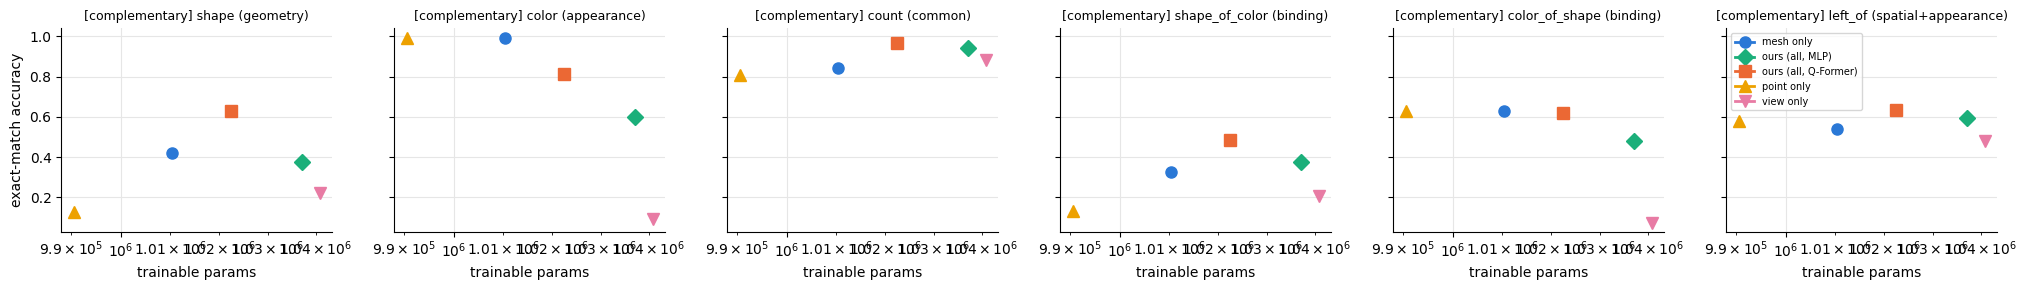

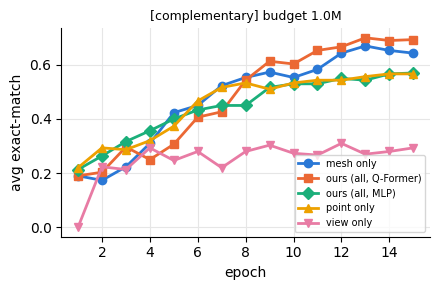

In [10]:
# ---------- Results ----------
import pandas as pd, matplotlib.pyplot as plt
df = pd.DataFrame([r for r in results if r.get("tag") == TAG])
cols = [c for c in ["cond", "setting", "rgb", "budget", "params"] + list(TASKS) + ["avg"] if c in df]   # rgb: point / mesh encoders got RGB
display(df[cols].sort_values(["budget", "cond", "setting"], ascending=[False, False, True]).round(3))

# fixed color + marker per setting (color follows the entity, identical in every panel; marker = second cue)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
STYLE = {name: dict(color=PALETTE[k], marker="osD^vP"[k]) for k, name in enumerate(list(SETTINGS) + ["textify + LoRA"])}
conds = [c for c in CONDITIONS if c in set(df["cond"])]

def _axes_style(ax):
    ax.grid(True, color="0.9", lw=0.8); ax.set_axisbelow(True)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

fig, axes = plt.subplots(len(conds), len(TASKS), figsize=(3.4 * len(TASKS), 3.0 * len(conds)), sharey=True, squeeze=False)
for row, cond in zip(axes, conds):
    for ax, t in zip(row, TASKS):
        for name, g in df[df["cond"] == cond].groupby("setting"):
            g = g.sort_values("params"); ax.plot(g["params"], g[t], lw=2, ms=8, label=name, **STYLE[name])
        ax.set_xscale("log"); ax.set_title(f"[{cond}] {t} ({TASKS[t]})", fontsize=9); _axes_style(ax)
    row[0].set_ylabel("exact-match accuracy")
for ax in axes[-1]: ax.set_xlabel("trainable params")
axes[0, -1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# learning curves (avg accuracy on the first curve_n test scenes after each epoch): flat at the end = converged
budgets = sorted(df["budget"].unique(), reverse=True)
fig, axes = plt.subplots(len(conds), len(budgets), figsize=(4.5 * len(budgets), 3.0 * len(conds)), sharey=True, squeeze=False)
for row, cond in zip(axes, conds):
    for ax, budget in zip(row, budgets):
        for _, r in df[(df["cond"] == cond) & (df["budget"] == budget)].iterrows():
            ax.plot([c["epoch"] for c in r["curve"]], [c["avg"] for c in r["curve"]], lw=2, ms=6, label=r["setting"], **STYLE[r["setting"]])
        ax.set_title(f"[{cond}] budget {budget/1e6:.1f}M", fontsize=9); _axes_style(ax)
    row[0].set_ylabel("avg exact-match")
for ax in axes[-1]: ax.set_xlabel("epoch")
axes[0, -1].legend(fontsize=7)
plt.tight_layout(); plt.show()


## 9. (Optional) Textify baseline

In [11]:
# ---------- (Optional) Textify baseline: colored point cloud as text, zero-shot, same LLM ----------
def textify(ex, n=64):
    idx = np.linspace(0, len(ex["points"]) - 1, n).astype(int)        # points are already shuffled
    hexes = ["#%02x%02x%02x" % tuple((np.clip(c, 0, 1) * 255).round().astype(int)) for c in ex["point_rgb"][idx]]
    pts = " ".join(f"({x:.2f},{y:.2f},{z:.2f}) {h}" for (x, y, z), h in zip(ex["points"][idx], hexes))
    names = ", ".join(COLORS)                                  # lit RGB, like every other representation; name the options
    return (f"Colored 3D point cloud, (x,y,z) and lit RGB: {pts}\nPossible colors: {names}. "
            f"Possible shapes: {', '.join(SHAPES)}.\nQuestion: {ex['q']} Answer with one word.")

NUM_WORDS = {"one": "1", "two": "2", "three": "3"}

@torch.no_grad()
def textify_zero_shot(data, n=100):
    hits = {}
    for ex in data[:n]:
        msgs = [{"role": "user", "content": textify(ex)}]
        # render the template to text, then tokenize: works on transformers 4.x and 5.x
        # (5.x returns a BatchEncoding from apply_chat_template(..., return_tensors="pt"), which generate() rejects)
        prompt = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
        enc = tok(prompt, return_tensors="pt", add_special_tokens=False).to(device)
        out = llm.generate(**enc, max_new_tokens=6, do_sample=False, pad_token_id=tok.eos_token_id)
        pred = tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip().lower()
        pred = pred.split()[0].strip(".,!\"'") if pred else ""
        pred = NUM_WORDS.get(pred, pred)                          # "three" -> "3" for the count task
        hits.setdefault(ex["task"], []).append(pred == ex["a"])
    res = {t: float(np.mean(v)) for t, v in hits.items()}; res["avg"] = float(np.mean(list(res.values())))
    return res

print("textify zero-shot:", textify_zero_shot(test_data))
print("tokens per textified prompt ≈", len(tok(textify(test_data[0]))["input_ids"]), "vs K =", CFG["K"])

textify zero-shot: {'shape': 0.0, 'color': 0.17647058823529413, 'count': 0.0, 'shape_of_color': 0.23529411764705882, 'color_of_shape': 0.1875, 'left_of': 0.0, 'avg': 0.09987745098039215}
tokens per textified prompt ≈ 1545 vs K = 16


## 10. Textify + LoRA at the same budget
The zero-shot prompt of section 9 (64 points as text: xyz + lit RGB hex, plus the lists of possible colors and shapes), but the LLM is fine-tuned with LoRA on its attention projections. Per-layer ranks are chosen so the LoRA has as many trainable parameters as the adaptors (`lora_plan`). Same train/test split, same teacher-forced exact match; it goes into `results.json` under the **matched** condition (it sees lit RGB, like the color=True encoders), so re-running section 8 adds it to the table and figures.

Cost: each prompt is ~1.6k tokens vs K = 16 soft tokens, so one epoch takes far longer than an adaptor run (the cell prints an ETA after 10 steps). Default is 1 epoch per budget; the adaptors get 8. Resumable like section 7; weights go to `ckpt/<TAG>/matched/textify_LoRA__<budget>M.pt`.

In [12]:
# ---------- Textify + LoRA: same input as section 9, same trainable-parameter budget as the adaptors ----------
# Run sections 7 and 9 first (TAG / CKPT_DIR / BUDGETS / textify). The LoRA is attached to the shared frozen LLM with
# forward hooks and detached again after every run, so the adaptor cells keep working on the untouched LLM.
LORA_NAME = "textify + LoRA"
LORA_CFG = dict(
    targets=("q_proj", "k_proj", "v_proj", "o_proj"),   # attention projections of every layer
    scale=2.0,             # W x + scale * B A x   (= alpha / r with alpha = 2r)
    epochs=1,              # ~1.6k tokens per example: one epoch costs several adaptor runs (ETA printed after 10 steps)
    batch_size=16, micro=8,  # optimizer batch / micro-batch (gradient accumulation); micro=4 if the T4 runs out of memory
    lr=5e-4, n_points=64,  # 64 points as text, exactly the zero-shot prompt
    n_curve=4,             # learning-curve points per run (accuracy on the first curve_n test scenes)
    grad_ckpt=True,        # recompute activations in backward: needed to fit 8 x 1.6k tokens on a T4
)

def lora_plan(budget, targets=LORA_CFG["targets"]):
    """Per-layer LoRA ranks whose total parameter count is closest to `budget` (ranks differ by at most 1)."""
    layers = llm.model.layers
    per = sum(getattr(layers[0].self_attn, t).in_features + getattr(layers[0].self_attn, t).out_features for t in targets)
    R = max(len(layers), round(budget / per))              # rank units summed over layers
    return [R // len(layers) + (l < R % len(layers)) for l in range(len(layers))], R * per

class TextLoRA(nn.Module):
    """LoRA on the frozen LLM's attention projections, B = 0 at init. `with lora:` attaches it for the block."""
    def __init__(self, ranks, targets=LORA_CFG["targets"], scale=LORA_CFG["scale"]):
        super().__init__()
        self.ranks, self.targets, self.scale = list(ranks), tuple(targets), scale
        self.A, self.B = nn.ParameterList(), nn.ParameterList(); self.sites, self.handles = [], []
        for l, r in enumerate(self.ranks):
            for t in self.targets:
                lin = getattr(llm.model.layers[l].self_attn, t); self.sites.append(lin)   # plain list: not saved
                self.A.append(nn.Parameter(torch.randn(r, lin.in_features) / math.sqrt(lin.in_features)))
                self.B.append(nn.Parameter(torch.zeros(lin.out_features, r)))
    def _hook(self, k):
        return lambda mod, inp, out: out + self.scale * F.linear(F.linear(inp[0], self.A[k]), self.B[k])
    def attach(self):
        if not self.handles: self.handles = [lin.register_forward_hook(self._hook(k)) for k, lin in enumerate(self.sites)]
        return self
    def detach(self):
        for h in self.handles: h.remove()
        self.handles = []
    def __enter__(self): return self.attach()
    def __exit__(self, *exc): self.detach()

def lora_encode(ex):
    """Chat prompt (the zero-shot one) -> token ids; answer = the bare answer word + EOS (<|im_end|>)."""
    msgs = [{"role": "user", "content": textify(ex, LORA_CFG["n_points"])}]
    p = tok(tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False), add_special_tokens=False)["input_ids"]
    return p, tok(ex["a"], add_special_tokens=False)["input_ids"] + [EOS], ex["task"]

def lora_collate(items):
    L = max(len(p) + len(a) for p, a, _ in items)
    ids = torch.full((len(items), L), EOS, dtype=torch.long); attn = torch.zeros(len(items), L, dtype=torch.long)
    ans = torch.zeros(len(items), L, dtype=torch.bool)
    for i, (p, a, _) in enumerate(items):
        ids[i, :len(p) + len(a)] = torch.tensor(p + a); attn[i, :len(p) + len(a)] = 1; ans[i, len(p):len(p) + len(a)] = True
    return dict(ids=ids, attn=attn, ans=ans, task=[t for _, _, t in items])

def lora_answer_logits(b):
    """Same as answer_logits, but the input is the text prompt instead of soft tokens."""
    with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
        h = llm.model(input_ids=b["ids"], attention_mask=b["attn"], use_cache=False).last_hidden_state
        sel = b["ans"][:, 1:]                                  # token i is predicted from position i-1
        logits = llm.lm_head(h[:, :-1][sel])
    return logits.float(), b["ids"][:, 1:][sel], sel.nonzero()[:, 0]

@torch.no_grad()
def lora_evaluate(items, bs=16):
    """Teacher-forced exact match, identical to evaluate()."""
    was = llm.training; llm.eval(); hits = {}
    for s in range(0, len(items), bs):
        b = to_dev(lora_collate(items[s:s + bs])); logits, tgt, ex = lora_answer_logits(b)
        wrong = torch.zeros(len(b["ids"]), device=device).index_add_(0, ex, (logits.argmax(-1) != tgt).float())
        for t, o in zip(b["task"], (wrong == 0).tolist()): hits.setdefault(t, []).append(o)
    llm.train(was)
    res = {t: float(np.mean(v)) for t, v in hits.items()}; res["avg"] = float(np.mean(list(res.values())))
    return res

def lora_train(lora, items, eval_items, cfg=LORA_CFG, log_every=50):
    bs, mb = cfg["batch_size"], cfg["micro"]
    opt = torch.optim.AdamW(lora.parameters(), lr=cfg["lr"], weight_decay=0.0); scaler = make_scaler()
    per_ep = math.ceil(len(items) / bs); steps = cfg["epochs"] * per_ep
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, cfg["lr"], total_steps=steps, pct_start=0.05)
    curve_at = set(np.linspace(0, steps, cfg["n_curve"] + 1)[1:].round().astype(int).tolist())
    curve, step, t0 = [], 0, time.time()
    for ep in range(cfg["epochs"]):
        idx = np.random.permutation(len(items))
        for s in range(0, len(items), bs):
            chunk = [items[i] for i in idx[s:s + bs]]; n_tok = sum(len(a) for _, a, _ in chunk); tot = 0.0
            opt.zero_grad(set_to_none=True)
            for m in range(0, len(chunk), mb):                 # mean over the answer tokens of the whole batch
                logits, tgt, _ = lora_answer_logits(to_dev(lora_collate(chunk[m:m + mb])))
                loss = F.cross_entropy(logits, tgt, reduction="sum") / n_tok
                scaler.scale(loss).backward(); tot += loss.item()
            scaler.step(opt); scaler.update(); sched.step(); step += 1
            if step == 10: print(f"  {(time.time() - t0) / 10:.2f} s/step -> ETA {(time.time() - t0) / 10 * steps / 60:.0f} min for {steps} steps")
            if step % log_every == 0: print(f"  ep {ep} step {step}/{steps} loss {tot:.3f}")
            if step in curve_at:
                curve.append(dict(epoch=round(step / per_ep, 3), **lora_evaluate(eval_items)))
                print(f"  -- epoch {curve[-1]['epoch']}: " + " ".join(f"{k} {v:.2f}" for k, v in curve[-1].items() if k != "epoch"))
    return curve

def lora_ckpt_path(budget): return os.path.join(CKPT_DIR, "matched", f"textify_LoRA__{budget / 1e6:g}M.pt")

def load_lora(budget):
    """Reload a trained LoRA. Usage: `with load_lora(1e6): print(lora_evaluate(TXT_TEST))`."""
    ck = torch.load(lora_ckpt_path(budget), map_location=device)
    lora = TextLoRA(ck["ranks"], ck["targets"], ck["scale"]).to(device); lora.load_state_dict(ck["state_dict"])
    return lora

# tokenize every prompt once (~1.6k tokens each)
t0 = time.time()
TXT_TRAIN = [lora_encode(ex) for ex in train_data]; TXT_TEST = [lora_encode(ex) for ex in test_data]
print(f"tokenized {len(TXT_TRAIN) + len(TXT_TEST)} prompts in {time.time() - t0:.0f}s, "
      f"mean length {np.mean([len(p) + len(a) for p, a, _ in TXT_TRAIN]):.0f} tokens")

# textify answers with lit RGB from the point cloud -> it belongs to the matched condition
results = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else []
for budget in BUDGETS:
    path = lora_ckpt_path(budget); os.makedirs(os.path.dirname(path), exist_ok=True)
    if any(r.get("tag") == TAG and r["setting"] == LORA_NAME and r["budget"] == budget and os.path.exists(r.get("ckpt", ""))
           for r in results): continue
    ranks, n = lora_plan(budget); set_seed(CFG["seed"])
    lora = TextLoRA(ranks).to(device); assert n_params(lora) == n
    print(f"\n== [matched] {LORA_NAME} | budget {budget/1e6:.1f}M -> ranks {min(ranks)}-{max(ranks)} on "
          f"{'/'.join(LORA_CFG['targets'])} x {len(ranks)} layers, {n/1e6:.2f}M params")
    if LORA_CFG["grad_ckpt"]: llm.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    t0 = time.time(); llm.train()                          # no dropout in Qwen2; train() only switches on checkpointing
    try:
        with lora:
            curve = lora_train(lora, TXT_TRAIN, TXT_TEST[:CFG["curve_n"]]); res = lora_evaluate(TXT_TEST)
    finally:
        llm.eval()
        if LORA_CFG["grad_ckpt"]: llm.gradient_checkpointing_disable()
    secs = time.time() - t0
    print({k: round(v, 3) for k, v in res.items()}, f"({secs:.0f}s)")
    torch.save(dict(state_dict=lora.state_dict(), ranks=ranks, targets=LORA_CFG["targets"], scale=LORA_CFG["scale"],
                    n_points=LORA_CFG["n_points"], tag=TAG, setting=LORA_NAME, budget=budget, cond="matched", res=res), path)
    results = [r for r in results if not (r.get("tag") == TAG and r["setting"] == LORA_NAME and r["budget"] == budget)]
    results.append(dict(setting=LORA_NAME, budget=budget, cond="matched", width=max(ranks), params=n, tag=TAG, secs=secs,
                        curve=curve, ckpt=path, **res))
    json.dump(results, open(RESULTS_PATH, "w"), indent=1)
    del lora; torch.cuda.empty_cache() if device == "cuda" else None
print("done; re-run section 8 to put textify + LoRA into the table and figures")


tokenized 8100 prompts in 28s, mean length 1586 tokens

== [matched] textify + LoRA | budget 1.0M -> ranks 7-8 on q_proj/k_proj/v_proj/o_proj x 24 layers, 1.00M params


/tmp/ipykernel_5404/750545210.py:94: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); step += 1


  8.07 s/step -> ETA 61 min for 450 steps
  ep 0 step 50/450 loss 0.734
  ep 0 step 100/450 loss 0.787
  -- epoch 0.249: shape 0.16 color 0.10 count 0.26 shape_of_color 0.12 color_of_shape 0.14 left_of 0.48 avg 0.21
  ep 0 step 150/450 loss 0.927
  ep 0 step 200/450 loss 0.775
  -- epoch 0.5: shape 0.02 color 0.34 count 0.26 shape_of_color 0.08 color_of_shape 0.36 left_of 0.48 avg 0.26
  ep 0 step 250/450 loss 0.795
  ep 0 step 300/450 loss 0.773
  -- epoch 0.751: shape 0.16 color 0.58 count 0.54 shape_of_color 0.08 color_of_shape 0.62 left_of 0.48 avg 0.41
  ep 0 step 350/450 loss 0.623
  ep 0 step 400/450 loss 0.748
  ep 0 step 450/450 loss 0.591
  -- epoch 1.0: shape 0.18 color 0.56 count 0.66 shape_of_color 0.18 color_of_shape 0.60 left_of 0.50 avg 0.45
{'shape': 0.153, 'color': 0.6, 'count': 0.607, 'shape_of_color': 0.08, 'color_of_shape': 0.62, 'left_of': 0.527, 'avg': 0.431} (3882s)
done; re-run section 8 to put textify + LoRA into the table and figures


## Notes from the CPU sanity check (no LLM; linear probe on adaptor outputs, 3k train scenes)
_Measured with the old renderer (16px unshaded point splatting); re-check with the rasterized 32px views._

| setting | shape | color | count | shape_of_color |
|---|---|---|---|---|
| view only | 0.27 | 0.97 | 0.94 | 0.25 |
| mesh only | 0.87 | 0.25 | 0.74 | 0.63 |
| point only | 0.21 | 0.26 | 0.75 | 0.28 |
| all, Q-Former, 12 epochs, no LayerNorm | 0.89 | 0.23 | 0.87 | 0.65 |
| all, Q-Former, 24 epochs, LayerNorm, rep-dropout 0.3 | 0.93 | 0.89 | 0.87 | 0.67 |

- Representations do carry different information (views → color, mesh → shape), as designed.
- Multi-rep models converge more slowly, and representation dropout slows them further → train to convergence, plot learning curves, don't compare at a fixed small epoch count.
- **Open issue:** `shape_of_color` stays ~0.65 for every setting. Color (views) and shape (mesh) both arrive, but nothing tells the aggregator which view pixel and which mesh vertex belong to the same object. Candidate fixes: shared 3D positional encoding for all tokens (unproject view pixels to 3D), question-conditioned queries.
- The point encoder is weak on shape (near chance) — worth tuning (more groups, local coordinates relative to group centers).
